In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_DOUBLE, set_font_size
GRID = False
FONT_SIZE = 18
set_font_size(FONT_SIZE)

## Proecedure

1. Change configuration file to include constrained linear spring:
    
    component=VirtualComponent(

        spring=ConstrainedLinearSpring(30.0,n=np.array([[1], [0], [1]])),
        damper=LinearDamper(5.0),
        s_param=1.0,
        name="lin_seg3",
    ),
    
    goal=go_x_y,
    
2. bash ../start_arm.sh
3. cd ConstrainedSpring && python3 ../VMC/GUI_MultiVMC_Torque.py
4. source publish_pos.sh

# Constrained vs Linear Spring: X-Y Plane Trajectory Comparison

Comparison of end-effector trajectories in the x-y plane for:
- **Constrained Spring** (k=90): Constrains motion to x-axis only (no y movement)
- **Linear Spring** (k=90): Allows free motion in both x and y directions

**Experiment:**
- Reference starts at x=0, y=0
- Reference moves to x=0.2 m
- Reference returns to x=0 m
- Time is color-coded to show trajectory evolution (blue → red)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.collections import LineCollection

# Load data
constrained_data = np.load('outputs/constrained_spring/constrained_k30.npz')
linear_data = np.load('outputs/constrained_spring/linear_k30.npz')

print(f"Constrained: {len(constrained_data['t'])} samples")
print(f"Linear: {len(linear_data['t'])} samples")

# Extract common variables
datasets = {
    'Constrained (k=90)': constrained_data,
    'Linear (k=90)': linear_data
}

# Find t=0 (when reference starts moving in x)
# and t=end (when reference returns to x=0)
trajectories = {}

for name, data in datasets.items():
    t = data['t']
    goal = data['goal']  # (n, N_VC, 3)
    comp_pos = data['comp_pos']  # (n, N_VC, 3)
    
    # Get reference x position
    ref_x = goal[:, 0, 0]  # First VC, x coordinate
    
    # Find when reference starts moving (ref_x != 0)
    nonzero_idx = np.where(np.abs(ref_x) > 1e-6)[0]
    t_start_idx = nonzero_idx[0] if len(nonzero_idx) > 0 else 0
    
    # Find when reference returns to near 0 (after reaching max)
    max_x_idx = np.argmax(np.abs(ref_x))
    returning = np.where(np.abs(ref_x[max_x_idx:]) < 1e-6)[0]
    t_end_idx = max_x_idx + returning[0] if len(returning) > 0 else len(ref_x) - 1
    
    # Extract trajectory window
    t_window = t[t_start_idx:t_end_idx]
    t_relative = t_window - t_window[0]  # Normalize to start at 0
    
    ee_pos = comp_pos[t_start_idx:t_end_idx, 0, :2]  # x, y positions
    ref_pos = goal[t_start_idx:t_end_idx, 0, :2]  # reference x, y
    
    trajectories[name] = {
        't': t_relative,
        'ee_xy': ee_pos,
        'ref_xy': ref_pos,
        'duration': t_relative[-1]
    }
    
    print(f"\n{name}:")
    print(f"  Duration: {trajectories[name]['duration']:.2f} s")
    print(f"  EE x range: [{ee_pos[:, 0].min():.4f}, {ee_pos[:, 0].max():.4f}] m")
    print(f"  EE y range: [{ee_pos[:, 1].min():.6f}, {ee_pos[:, 1].max():.6f}] m")

Constrained: 3616 samples
Linear: 3237 samples

Constrained (k=90):
  Duration: 10.96 s
  EE x range: [-0.0000, 0.2708] m
  EE y range: [-0.003717, 0.000028] m

Linear (k=90):
  Duration: 9.80 s
  EE x range: [-0.0000, 0.2275] m
  EE y range: [-0.000007, 0.210069] m


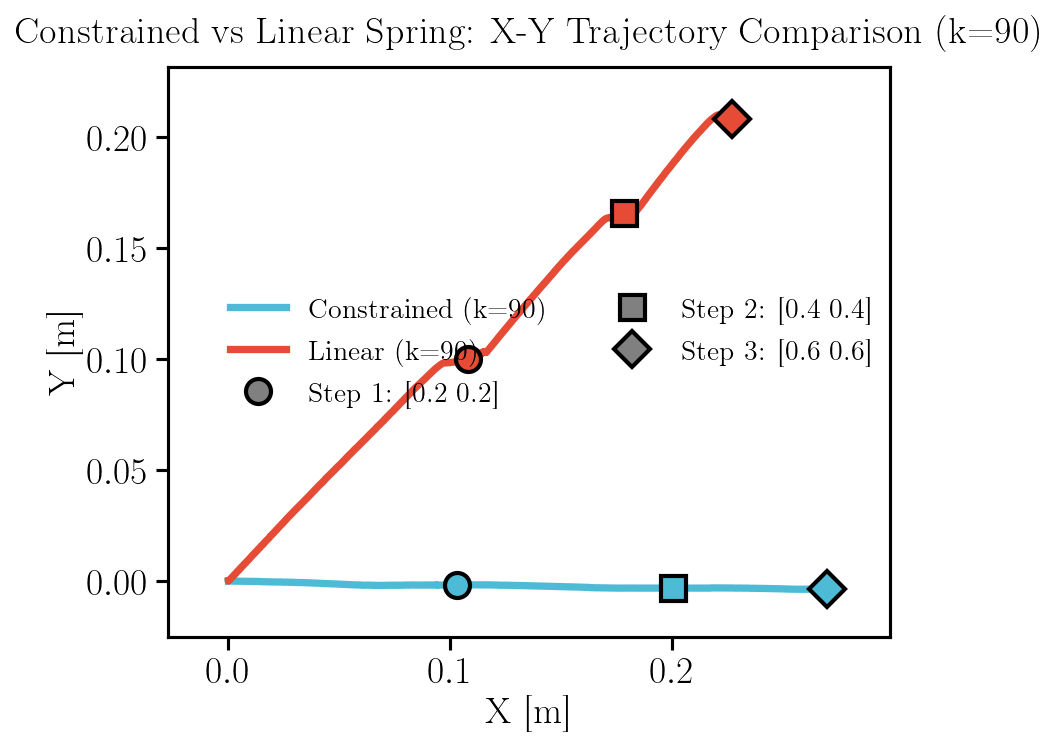


✓ Trajectory comparison complete
  Blue = Constrained spring (confined to x-axis)
  Red = Linear spring (free 2D motion)
  Markers placed 2 seconds after reference step change:
    ○ = Step 1 [0.2,0.2]
    □ = Step 2 [0.4,0.4]
    ◇ = Step 3 [0.6,0.6]


In [3]:
# Reference step positions (from bash script)
ref_steps = np.array([
    [0.2, 0.2],  # Step 1: x=0.2, y=0.2
    [0.4, 0.4],  # Step 2: x=0.4, y=0.4
    [0.6, 0.6],  # Step 3: x=0.6, y=0.6
])

# Markers for all three steps
step_markers = ['o', 's', 'D']  # circle for step 1, square for step 2, diamond for step 3
marker_size = 12
time_shift = 1.0  # [s] Shift markers by 2 seconds after reference step change

def find_step_indices_with_shift(t, ref_xy, time_shift):
    """Find indices where reference reaches each step, plus time_shift offset."""
    step_indices = []
    for step in ref_steps:
        distances = np.linalg.norm(ref_xy - step, axis=1)
        step_time_idx = np.argmin(distances)
        step_time = t[step_time_idx]
        
        # Find index at time + shift
        target_time = step_time + time_shift
        time_diffs = np.abs(t - target_time)
        shifted_idx = np.argmin(time_diffs)
        
        step_indices.append(shifted_idx)
    return step_indices

# Plot: X-Y plane comparison on SAME graph
fig, ax = plt.subplots(figsize=(FIG_W_DOUBLE, FIG_W_DOUBLE * 0.75))

# Color and style for each configuration
config_styles = {
    'Constrained (k=90)': {'color': COLORS[0], 'ee_lw': 3.5},
    'Linear (k=90)': {'color': COLORS[1], 'ee_lw': 3.5}
}

# Plot both trajectories
for config_idx, (name, traj) in enumerate(trajectories.items()):
    t = traj['t']
    ee_xy = traj['ee_xy']
    color = config_styles[name]['color']
    
    # Solid line: end-effector trajectory
    ax.plot(ee_xy[:, 0], ee_xy[:, 1], 
            color=color, linewidth=config_styles[name]['ee_lw'], 
            label=f'{name}', zorder=3)
    
    # Find and mark step positions on end-effector trajectory (with 2s shift)
    step_indices = find_step_indices_with_shift(t, traj['ref_xy'], time_shift)
    
    for step_num, idx in enumerate(step_indices):
        marker = step_markers[step_num]
        
        if idx < len(ee_xy):
            ax.plot(ee_xy[idx, 0], ee_xy[idx, 1], 
                    marker=marker, color=color, markersize=marker_size, 
                    markeredgewidth=2, markeredgecolor='black', 
                    markerfacecolor=color, zorder=5)

# Add legend for step markers
from matplotlib.lines import Line2D
step_legend = [Line2D([0], [0], marker=step_markers[i], color='w', 
                      markerfacecolor='gray', markeredgecolor='black', 
                      markeredgewidth=2, markersize=12, label=f'Step {i+1}: {ref_steps[i]}')
               for i in range(len(ref_steps))]

# Combine legends
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles + step_legend, loc='best', 
         framealpha=0.95, ncol=2)

# Labels and formatting
ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')
ax.set_title('Constrained vs Linear Spring: X-Y Trajectory Comparison (k=90)')
ax.grid(GRID)
ax.set_aspect('equal')

# Auto-scale with 10% padding, anchored to include the origin (reference starts at 0,0)
all_ee_points = np.vstack([traj['ee_xy'] for traj in trajectories.values()])

x_margin = (all_ee_points[:, 0].max() - all_ee_points[:, 0].min()) * 0.1
y_margin = (all_ee_points[:, 1].max() - all_ee_points[:, 1].min()) * 0.1
ax.set_xlim(min(0, all_ee_points[:, 0].min()) - x_margin, all_ee_points[:, 0].max() + x_margin)
ax.set_ylim(min(0, all_ee_points[:, 1].min()) - y_margin, all_ee_points[:, 1].max() + y_margin)

plt.tight_layout()
plt.savefig(os.path.join('outputs', 'constrained_spring', 'xy_trajectory_markers.pdf'))
plt.show()

print("\n✓ Trajectory comparison complete")
print("  Blue = Constrained spring (confined to x-axis)")
print("  Red = Linear spring (free 2D motion)")
print("  Markers placed 2 seconds after reference step change:")
print("    ○ = Step 1 [0.2,0.2]")
print("    □ = Step 2 [0.4,0.4]")
print("    ◇ = Step 3 [0.6,0.6]")

In [4]:
# Summary: Y-axis motion comparison
print("\n=== Y-AXIS MOTION COMPARISON ===")
print(f"{'Type':<20} | {'Y Min [m]':>12} | {'Y Max [m]':>12} | {'Y Range [m]':>12}")
print("-" * 60)

for name, traj in trajectories.items():
    ee_xy = traj['ee_xy']
    y_min = ee_xy[:, 1].min()
    y_max = ee_xy[:, 1].max()
    y_range = y_max - y_min
    print(f"{name:<20} | {y_min:>12.6f} | {y_max:>12.6f} | {y_range:>12.6f}")

print("\n→ Constrained spring: Y range ≈ 0 (confined to x-axis)")
print("→ Linear spring: Y range > 0 (free motion in both axes)")


=== Y-AXIS MOTION COMPARISON ===
Type                 |    Y Min [m] |    Y Max [m] |  Y Range [m]
------------------------------------------------------------
Constrained (k=90)   |    -0.003717 |     0.000028 |     0.003746
Linear (k=90)        |    -0.000007 |     0.210069 |     0.210076

→ Constrained spring: Y range ≈ 0 (confined to x-axis)
→ Linear spring: Y range > 0 (free motion in both axes)
